There are two main types of hierarchical clustering:

1. Agglomerative (Bottom-Up) – Start with each data point as its own cluster and merge them iteratively.
2. Divisive (Top-Down) – Start with all data points in one cluster and split them iteratively.

# Agglomerative

1. Step 1: Compute the Distance Matrix
    - First, calculate the distance (or dissimilarity) between each pair of data points.
    - Common distance metrics: Euclidean distance, Manhattan distance, Cosine similarity, etc.
    - Store these distances in a distance matrix.
2. Step 2: Start with Each Point as Its Own Cluster
    - Initially, each data point is considered its own cluster.
    - So, if there are N data points, we start with N clusters.
3. Step 3: Merge the Closest Clusters
    - Find the two closest clusters based on their distance.
    - Merge them into a new cluster.
    - Update the distance matrix to reflect the new cluster.
4. Step 4: Update Distance Matrix (Linkage Method)

    - The way we measure the distance between clusters depends on the linkage method:
    - Single Linkage: Distance between the closest points of two clusters.
    - Complete Linkage: Distance between the farthest points of two clusters.
    - Average Linkage: Average distance between all points in the two clusters.
    - Centroid Linkage: Distance between the centroids (mean points) of two clusters.
5. Step 5: Repeat Until One Cluster Remains

    - Keep merging the closest clusters step by step.
    - Stop when all points are in a single cluster.
    - The process creates a hierarchical tree (dendrogram).
6. Step 6: Choose the Optimal Number of Clusters
    - Cut the dendrogram at a certain level to decide the number of clusters.
    - The number of clusters can be chosen manually by analyzing the dendrogram or using a threshold.

## Use case
1. $O(N^3) $ complexity, hence used for small datasets
2. When clusters aren’t well-separated but still hierarchical: Think of social networks or document classification, where clusters have sub-clusters.

## Scipy's implementation

Distance Matrix:
 [[0.         0.5017136  0.82421549 0.32755369 0.33198071 0.35447574]
 [0.5017136  0.         0.72642889 0.72506609 0.17058938 0.8024531 ]
 [0.82421549 0.72642889 0.         0.71690251 0.7091551  0.8251064 ]
 [0.32755369 0.72506609 0.71690251 0.         0.56557921 0.11030352]
 [0.33198071 0.17058938 0.7091551  0.56557921 0.         0.63684727]
 [0.35447574 0.8024531  0.8251064  0.11030352 0.63684727 0.        ]]
Cluster assignments based on cutting: [3 1 4 2 1 2]
Clusters using num_clusters = 2, : [1 1 2 1 1 1]


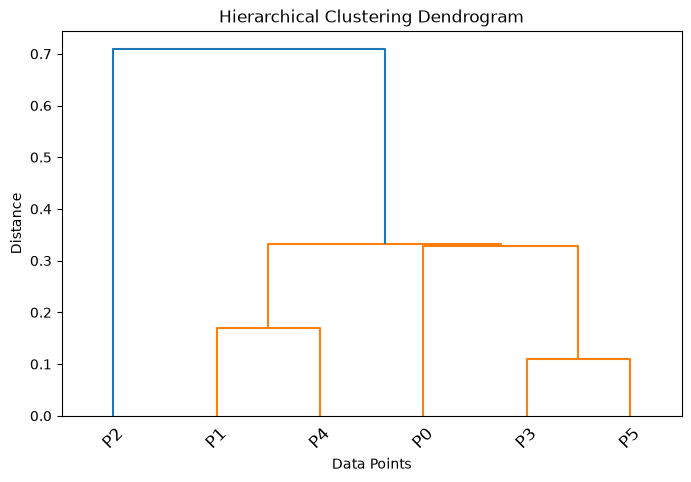

In [1]:
import numpy as np
import scipy.spatial.distance as dist
import matplotlib.pyplot as plt
import scipy.cluster.hierarchy as sch

# Generate sample data
np.random.seed(42)
X = np.random.rand(6, 2)  # 6 data points in 2D space

# Step 1: Compute Distance Matrix
distance_matrix = dist.pdist(X, metric='euclidean')  # Pairwise distances
distance_matrix = dist.squareform(distance_matrix)  # Convert to matrix form
print("Distance Matrix:\n", distance_matrix)

# Step 2-5: Perform Hierarchical Clustering using linkage
linkage_matrix = sch.linkage(X, method='single')  # Single linkage method


# assign each point to a cluster
# Option 1: Cut based on a distance threshold
threshold = 0.3  # Example threshold
clusters = sch.fcluster(linkage_matrix, t=threshold, criterion='distance')
print("Cluster assignments based on cutting:", clusters)

# Option 2: Cut to obtain a specific number of clusters
num_clusters = 2  # Example number of clusters
clusters = sch.fcluster(linkage_matrix, t=num_clusters, criterion='maxclust')
print(f"Clusters using num_clusters = {num_clusters}, : {clusters}")

# Step 6: Plot the Dendrogram
plt.figure(figsize=(8, 5))
sch.dendrogram(linkage_matrix, labels=[f"P{i}" for i in range(len(X))], 
               leaf_rotation=45, leaf_font_size=12)
plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Data Points")
plt.ylabel("Distance")
plt.show()


In [2]:
linkage_matrix

array([[3.        , 5.        , 0.11030352, 2.        ],
       [1.        , 4.        , 0.17058938, 2.        ],
       [0.        , 6.        , 0.32755369, 3.        ],
       [7.        , 8.        , 0.33198071, 5.        ],
       [2.        , 9.        , 0.7091551 , 6.        ]])

In [3]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score

# Option 2 equivalent: fixed number of clusters, same linkage as the scipy run above
ac = AgglomerativeClustering(n_clusters=num_clusters, linkage='single')
sk_labels = ac.fit_predict(X)
print("sklearn labels:", sk_labels)
print("scipy labels:  ", clusters)
# label ids differ (sklearn starts at 0, scipy at 1), so compare the partitions, not the raw ids
print("Same partition:", adjusted_rand_score(clusters, sk_labels) == 1.0)

# Option 1 equivalent: cut by distance threshold instead of a cluster count
ac_thresh = AgglomerativeClustering(n_clusters=None, distance_threshold=threshold, linkage='single')
sk_thresh_labels = ac_thresh.fit_predict(X)
print(f"\nsklearn labels (threshold={threshold}):", sk_thresh_labels)
print("Number of clusters found:", ac_thresh.n_clusters_)

# children_ is sklearn's merge history: row i merges two nodes, ids >= N are clusters made at row (id - N)
# same merge order as the first two columns of scipy's linkage_matrix
print("\nMerge history:\n", ac_thresh.children_)

sklearn labels: [0 0 1 0 0 0]
scipy labels:   [1 1 2 1 1 1]
Same partition: True

sklearn labels (threshold=0.3): [3 0 1 2 0 2]
Number of clusters found: 4

Merge history:
 [[3 5]
 [4 1]
 [0 6]
 [8 7]
 [9 2]]
